In [1]:
# CAREER NAVIGATOR
# ANN - CAREER READINESS PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import random
import warnings
import tensorflow as tf

from pathlib import Path

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_ROOT)
print("Processed Data:", PROCESSED_DIR)
print("Model Directory:", MODEL_DIR)
print("Report Directory:", REPORT_DIR)

Project Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator
Processed Data: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\dataset\processed
Model Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models
Report Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation


In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy").astype("float32")
X_val = np.load(PROCESSED_DIR / "X_val.npy").astype("float32")
X_test = np.load(PROCESSED_DIR / "X_test.npy").astype("float32")

y_train = np.load(
    PROCESSED_DIR / "y_train_readiness.npy"
).astype("int32")

y_val = np.load(
    PROCESSED_DIR / "y_val_readiness.npy"
).astype("int32")

y_test = np.load(
    PROCESSED_DIR / "y_test_readiness.npy"
).astype("int32")

print("Career readiness dataset loaded successfully!")

print("\nInput dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget dimensions:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Career readiness dataset loaded successfully!

Input dimensions:
Training: (10500, 65)
Validation: (2250, 65)
Testing: (2250, 65)

Target dimensions:
Training: (10500,)
Validation: (2250,)
Testing: (2250,)


In [4]:
readiness_encoder = joblib.load(
    MODEL_DIR / "readiness_encoder.joblib"
)

class_names = readiness_encoder.classes_
num_classes = len(class_names)

print("Career Readiness Classes:", class_names)
print("Number of Classes:", num_classes)

print("\nEncoded class mapping:")

for index, class_name in enumerate(class_names):
    print(f"{index} = {class_name}")

assert num_classes == 3, "Expected exactly three readiness classes."
assert set(np.unique(y_train)) == set(range(num_classes))

Career Readiness Classes: ['High' 'Low' 'Moderate']
Number of Classes: 3

Encoded class mapping:
0 = High
1 = Low
2 = Moderate


,Class,Count,Percentage
0,High,2608,24.84
1,Low,2619,24.94
2,Moderate,5273,50.22


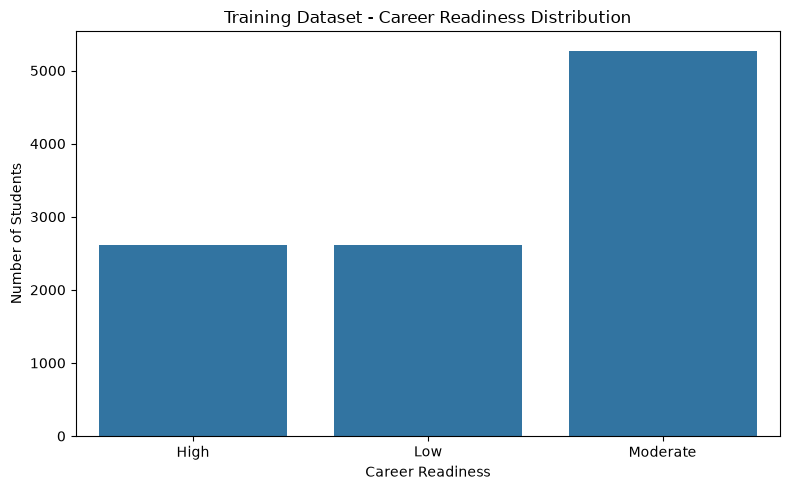

In [5]:
readiness_distribution = pd.DataFrame({
    "Class": class_names,
    "Count": [
        np.sum(y_train == index)
        for index in range(num_classes)
    ]
})

readiness_distribution["Percentage"] = (
    readiness_distribution["Count"] /
    len(y_train) * 100
)

display(readiness_distribution.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=readiness_distribution,
    x="Class",
    y="Count"
)

plt.title("Training Dataset - Career Readiness Distribution")
plt.xlabel("Career Readiness")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [6]:
readiness_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(num_classes, activation="softmax")
])

readiness_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

readiness_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,883 (73.76 KB)

 Trainable params: 18,883 (73.76 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
readiness_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "ann_readiness_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

print("Career readiness callbacks configured successfully!")

Career readiness callbacks configured successfully!


In [8]:
readiness_history = readiness_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=readiness_callbacks,
    verbose=1
)

print("\nCareer readiness ANN training completed!")
print("Epochs trained:", len(readiness_history.history["loss"]))
print("Best validation loss:", min(readiness_history.history["val_loss"]))

Epoch 1/100
302/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6884 - loss: 0.6724
Epoch 1: val_loss improved from None to 0.53262, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_readiness_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_readiness_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6912 - loss: 0.6668 - val_accuracy: 0.7582 - val_loss: 0.5326 - learning_rate: 0.0010
Epoch 2/100
305/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7552 - loss: 0.5532
Epoch 2: val_loss improved from 0.53262 to 0.52386, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_readiness_best.keras

Epoch 2: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_readiness_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7548 - loss: 0.5538 - val_a

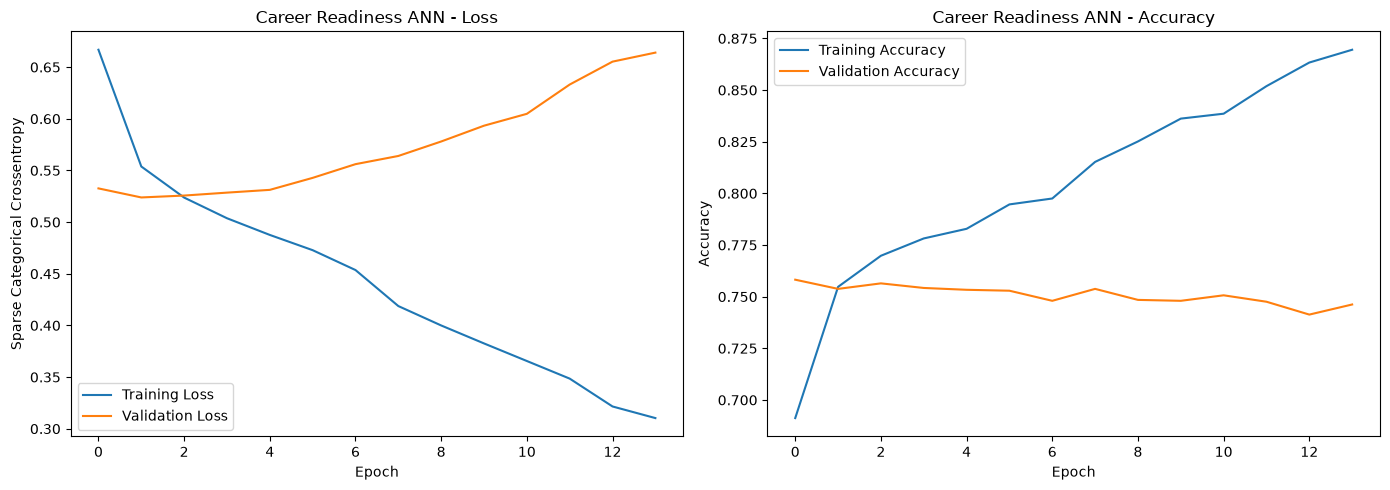

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    readiness_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    readiness_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Career Readiness ANN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Sparse Categorical Crossentropy")
axes[0].legend()

axes[1].plot(
    readiness_history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    readiness_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Career Readiness ANN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
readiness_probabilities = readiness_ann.predict(
    X_val,
    verbose=0
)

readiness_predictions = np.argmax(
    readiness_probabilities,
    axis=1
)

print("Validation predictions generated!")

print("\nSample predicted probabilities:")
display(pd.DataFrame(
    readiness_probabilities[:10],
    columns=class_names
).round(4))

print("\nSample predicted classes:")
print(readiness_encoder.inverse_transform(
    readiness_predictions[:10]
))

Validation predictions generated!

Sample predicted probabilities:


,High,Low,Moderate
0,0.0001,0.8520,0.1479
1,0.0661,0.1876,0.7463
2,0.0022,0.7030,0.2948
3,0.3026,0.0261,0.6713
4,0.2662,0.0115,0.7224
5,0.0000,0.9947,0.0053
6,0.7792,0.0002,0.2205
7,0.0005,0.8100,0.1895
8,0.0003,0.6841,0.3156
9,0.6468,0.0012,0.3520



Sample predicted classes:
['Low' 'Moderate' 'Low' 'Moderate' 'Moderate' 'Low' 'High' 'Low' 'Low'
 'High']


In [11]:
readiness_ann_results = {
    "Model": "ANN",

    "Accuracy": accuracy_score(
        y_val,
        readiness_predictions
    ),

    "Precision_Macro": precision_score(
        y_val,
        readiness_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall_Macro": recall_score(
        y_val,
        readiness_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Macro": f1_score(
        y_val,
        readiness_predictions,
        average="macro",
        zero_division=0
    ),

    "F1_Weighted": f1_score(
        y_val,
        readiness_predictions,
        average="weighted",
        zero_division=0
    ),

    "ROC_AUC": roc_auc_score(
        y_val,
        readiness_probabilities,
        multi_class="ovr",
        average="macro",
        labels=np.arange(num_classes)
    )
}

readiness_ann_results_df = pd.DataFrame([
    readiness_ann_results
])

display(readiness_ann_results_df.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,ANN,0.7538,0.7513,0.764,0.757,0.7535,0.9083


In [12]:
readiness_report = classification_report(
    y_val,
    readiness_predictions,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

readiness_report_df = pd.DataFrame(
    readiness_report
).transpose()

display(readiness_report_df.round(4))

readiness_report_df.to_csv(
    REPORT_DIR / "ann_readiness_classification_report.csv"
)

print("Career readiness classification report saved!")

,precision,recall,f1-score,support
High,0.7537,0.7806,0.7669,588.0000
Low,0.7362,0.7903,0.7623,558.0000
Moderate,0.7639,0.7210,0.7418,1104.0000
accuracy,0.7538,0.7538,0.7538,0.7538
macro avg,0.7513,0.7640,0.7570,2250.0000
weighted avg,0.7544,0.7538,0.7535,2250.0000


Career readiness classification report saved!


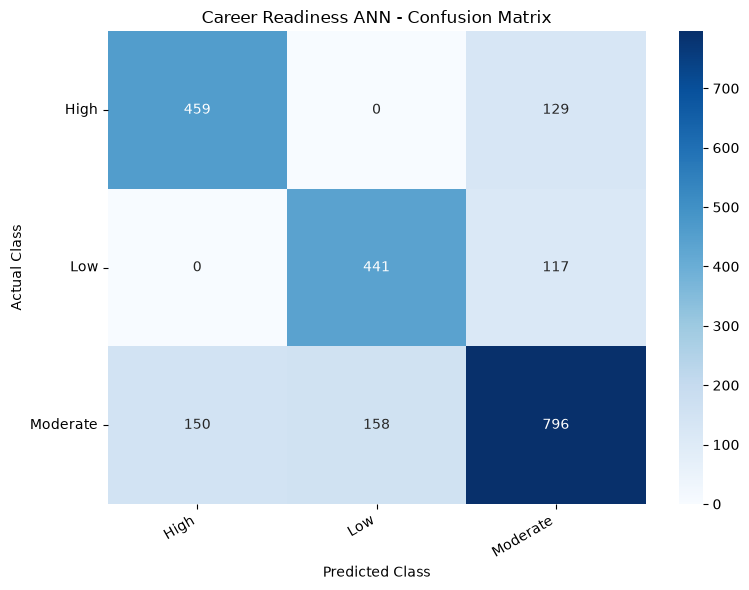

In [13]:
cm = confusion_matrix(
    y_val,
    readiness_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Career Readiness ANN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [14]:
baseline_candidates = [
    REPORT_DIR / "baseline_model_results.csv",
    REPORT_DIR / "baseline_classification_results.csv"
]

baseline_path = next(
    (path for path in baseline_candidates if path.exists()),
    None
)

if baseline_path is None:
    raise FileNotFoundError(
        "Baseline results CSV not found. "
        "Check reports/evaluation for the saved baseline results."
    )

baseline_df = pd.read_csv(baseline_path)

readiness_baseline = baseline_df[
    baseline_df["Task"] == "Career Readiness"
].copy()

if readiness_baseline.empty:
    raise ValueError(
        "Career Readiness results were not found in the baseline CSV."
    )

print("Baseline readiness results loaded successfully!")
display(readiness_baseline)

Baseline readiness results loaded successfully!


,Task,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC,MAE,MSE,RMSE,R2
3,Career Readiness,Logistic Regression,0.776889,0.788403,0.764014,0.774639,0.776619,0.913808,NaN,NaN,NaN,NaN
4,Career Readiness,Random Forest,0.732889,0.768817,0.696167,0.720680,0.729534,0.884842,NaN,NaN,NaN,NaN
5,Career Readiness,Decision Tree,0.596444,0.593972,0.593469,0.593710,0.596397,0.686272,NaN,NaN,NaN,NaN


In [15]:
baseline_comparison = readiness_baseline[
    [
        "Model",
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "F1_Weighted",
        "ROC_AUC"
    ]
].copy()

ann_comparison = pd.DataFrame([{
    "Model": "ANN",
    "Accuracy": readiness_ann_results["Accuracy"],
    "Precision_Macro": readiness_ann_results["Precision_Macro"],
    "Recall_Macro": readiness_ann_results["Recall_Macro"],
    "F1_Macro": readiness_ann_results["F1_Macro"],
    "F1_Weighted": readiness_ann_results["F1_Weighted"],
    "ROC_AUC": readiness_ann_results["ROC_AUC"]
}])

readiness_comparison = pd.concat(
    [baseline_comparison, ann_comparison],
    ignore_index=True
)

readiness_comparison = readiness_comparison.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

print("CAREER READINESS - BASELINE VS ANN")
print("=" * 65)

display(readiness_comparison.round(4))

CAREER READINESS - BASELINE VS ANN


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Logistic Regression,0.7769,0.7884,0.7640,0.7746,0.7766,0.9138
1,ANN,0.7538,0.7513,0.7640,0.7570,0.7535,0.9083
2,Random Forest,0.7329,0.7688,0.6962,0.7207,0.7295,0.8848
3,Decision Tree,0.5964,0.5940,0.5935,0.5937,0.5964,0.6863


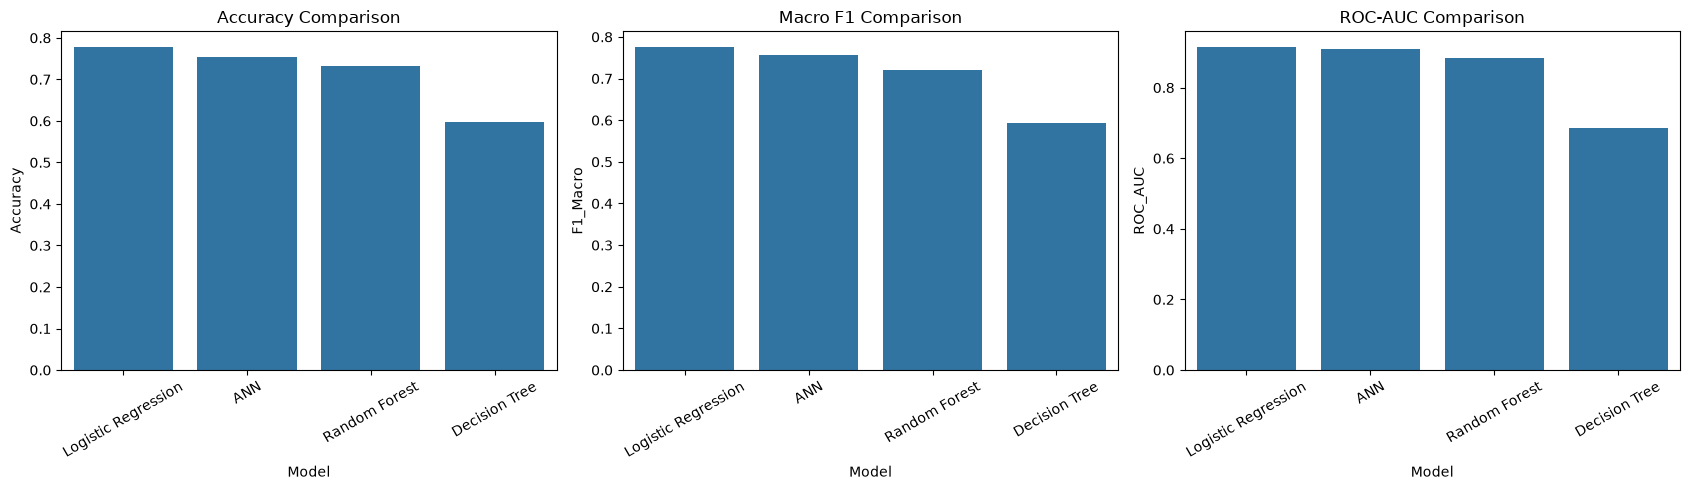

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("Accuracy", "Accuracy Comparison"),
    ("F1_Macro", "Macro F1 Comparison"),
    ("ROC_AUC", "ROC-AUC Comparison")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=readiness_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [17]:
readiness_ann.save(
    MODEL_DIR / "ann_readiness_final.keras"
)

pd.DataFrame(
    readiness_history.history
).to_csv(
    REPORT_DIR / "ann_readiness_training_history.csv",
    index=False
)

readiness_ann_results_df.to_csv(
    REPORT_DIR / "ann_readiness_metrics.csv",
    index=False
)

readiness_comparison.to_csv(
    REPORT_DIR / "readiness_baseline_ann_comparison.csv",
    index=False
)

print("Career readiness ANN artifacts saved successfully!")

Career readiness ANN artifacts saved successfully!


In [18]:
readiness_artifacts = [
    MODEL_DIR / "ann_readiness_best.keras",
    MODEL_DIR / "ann_readiness_final.keras",

    REPORT_DIR / "ann_readiness_training_history.csv",
    REPORT_DIR / "ann_readiness_metrics.csv",
    REPORT_DIR / "ann_readiness_classification_report.csv",
    REPORT_DIR / "readiness_baseline_ann_comparison.csv"
]

missing_artifacts = []

print("CAREER READINESS ANN - ARTIFACT VERIFICATION")
print("=" * 65)

for artifact in readiness_artifacts:

    exists = artifact.exists()

    print(
        f"{artifact.name}:",
        "FOUND" if exists else "MISSING"
    )

    if not exists:
        missing_artifacts.append(artifact.name)

print("\nMissing artifacts:", missing_artifacts)

assert not missing_artifacts, "Some readiness ANN artifacts are missing!"

print("\nALL CAREER READINESS ANN ARTIFACTS VERIFIED!")

CAREER READINESS ANN - ARTIFACT VERIFICATION
ann_readiness_best.keras: FOUND
ann_readiness_final.keras: FOUND
ann_readiness_training_history.csv: FOUND
ann_readiness_metrics.csv: FOUND
ann_readiness_classification_report.csv: FOUND
readiness_baseline_ann_comparison.csv: FOUND

Missing artifacts: []

ALL CAREER READINESS ANN ARTIFACTS VERIFIED!
